# Deep Learning Statistical Arbitrage, en un seul notebook

Ce notebook reproduit le papier de Guijarro-Ordonez, Pelger et Zanotti sur les grandes actions américaines de 1998 à 2016.

1. **Hedge** : pour chaque action, le résidu est son rendement moins la partie expliquée par K facteurs (Fama-French, PCA ou IPCA).
2. **Signal** : une politique lit les 30 derniers jours de chaque résidu cumulé et lui donne un poids (OU+Threshold, Fourier+FFN ou CNN+Transformer).
3. **Allocation** : les poids sont normalisés (levier de 1). Les politiques à réseau de neurones sont entraînées à maximiser le ratio de Sharpe sur 1000 jours, puis testées sur les 125 jours suivants, en fenêtres glissantes.

La section 7 relance la même stratégie avec les **expériences de robustesse** du papier.

Tout est enregistré dans `DOSSIER` (ton Drive sur Colab) : données, résidus, modèles entraînés et résultats. Après avoir changé un paramètre, relance **tout** le notebook : ce qui est déjà calculé est rechargé.

In [1]:
# ===================== PARAMÈTRES =====================
FACTOR_MODEL = "IPCA"        # "FamaFrench", "PCA" ou "IPCA"
K = 5                        # FamaFrench : 0, 1, 3, 5, 8 | PCA, IPCA : 0, 1, 3, 5, 8, 10, 15
POLITIQUE = "CNNTransformer" # "OUThreshold" (sans apprentissage), "FourierFFN" ou "CNNTransformer"
TRAINING = "pretrained"      # "pretrained" : réseaux des auteurs (entraînés sur IPCA 5) | "train" : entraînement ici
EPOCHS = 100                 # époques par fenêtre (papier : 100)
COMPOSITION = True           # True : levier sur les positions en actions (papier) ; False : sur les résidus
MAX_WINDOWS = None           # None : toutes les fenêtres ; ex. 2 pour un essai rapide
ROBUSTESSE = False           # True : lance aussi les expériences de robustesse (section 7)
DOSSIER = "/content/drive/MyDrive/DLSA"   # sur ton ordinateur, par exemple "DLSA"

In [2]:
import glob, io, os, re, zipfile
import numpy as np, pandas as pd, requests, scipy.linalg, torch, torch.nn as nn
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view
from torch.utils.checkpoint import checkpoint

if DOSSIER.startswith("/content/drive"):
    from google.colab import drive
    drive.mount("/content/drive")
os.makedirs(f"{DOSSIER}/resultats", exist_ok=True)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Calcul sur :", torch.cuda.get_device_name(0) if device == "cuda" else "CPU")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Calcul sur : Tesla T4


## 1. Données

Les données publiées par les auteurs sont téléchargées une fois dans `DOSSIER` (3,3 Go) : rendements quotidiens et caractéristiques mensuelles (CRSP), plus leurs réseaux entraînés. Les facteurs de Fama-French viennent du site de Kenneth French.

In [3]:
DROPBOX = "https://www.dropbox.com/scl/fo/di9dls4pj7p9i7jkz6ibh/{}?rlkey=2yfxdvj5niaowja7n76icyvcg&dl=1"
SOURCES = {
    "rendements.csv": "ABqdMjsyAuBlLMctOV0MmbM/data/daily-returns-replication.csv",
    "caracteristiques.csv": "AM9OWyhIhu78iusGD7ocPFc/data/characteristics-replication.csv",
}
DOSSIERS_AUTEURS = {   # réseaux entraînés par les auteurs, un dossier par expérience
    "principale": "ABhJIbgUEMlas4yOe2eOrTY/trained-models/main-replication",
    "meanvar": "AA0j-DqsDKlX0-9x7iZO0jw/trained-models/meanvar-replication",
    "lookback60": "AEA4w_lqSNqIOtyQttXc8NI/trained-models/lookback60-replication",
    "constant-4year": "ANbfhfyaFeEcqdT-9dtyZ_g/trained-models/constant-4year-replication",
    "constant-8year": "APtAhmBVknYvZkkgaxQ9oj8/trained-models/constant-8year-replication",
    "frictions": "AAGgZRonF0oD8VUxjIcvhw8/trained-models/frictions-replication",
    "multiholding": "ANhHyQzSSYLAlPf-9-_LviY/trained-models/multiholding-replication",
    "overlapping": "AFoX_Ou1iwDGjSQS5NKkeN8/trained-models/overlapping-replication",
}
SOURCES.update({f"modeles_{k}.zip": v for k, v in DOSSIERS_AUTEURS.items()})


def telecharger(nom):
    """Télécharge un fichier des auteurs dans DOSSIER, s'il n'y est pas déjà."""
    chemin = f"{DOSSIER}/{nom}"
    if not os.path.exists(chemin):
        print("Téléchargement de", nom)
        with requests.get(DROPBOX.format(SOURCES[nom]), stream=True, headers={"User-Agent": "Mozilla/5.0"}) as r:
            r.raise_for_status()
            with open(chemin + ".part", "wb") as f:
                for bloc in r.iter_content(1 << 20):
                    f.write(bloc)
        os.replace(chemin + ".part", chemin)
    return chemin


def fama_french():
    """Facteurs quotidiens de Fama-French (décimaux) : 5 facteurs, momentum, 2 retournements et taux sans risque."""
    chemin = f"{DOSSIER}/fama_french.csv"
    if os.path.exists(chemin):
        return pd.read_csv(chemin, index_col=0)
    tables = []
    for nom in ["F-F_Research_Data_5_Factors_2x3", "F-F_Momentum_Factor", "F-F_ST_Reversal_Factor", "F-F_LT_Reversal_Factor"]:
        url = f"https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/{nom}_daily_CSV.zip"
        z = zipfile.ZipFile(io.BytesIO(requests.get(url).content))
        lignes = z.read(z.namelist()[0]).decode("latin-1").splitlines()
        debut = next(i for i, l in enumerate(lignes) if re.match(r"\s*\d{8}\s*,", l))
        texte = "\n".join([lignes[debut - 1]] + [l for l in lignes[debut:] if re.match(r"\s*\d{8}\s*,", l)])
        tables.append(pd.read_csv(io.StringIO(texte), index_col=0) / 100)
    ff = pd.concat(tables, axis=1, join="inner")
    ff.columns = ff.columns.str.strip()
    ff = ff[["Mkt-RF", "SMB", "HML", "RMW", "CMA", "Mom", "ST_Rev", "LT_Rev", "RF"]]
    ff.to_csv(chemin)
    return ff


FF = fama_french()

Les deux CSV sont résumés une fois pour toutes dans `donnees.npz` :
- **les rendements quotidiens en excès du taux sans risque** (jours × actions, à partir de 1996) ;
- **l'univers de chaque mois** : les actions dont la capitalisation dépasse 0,01 % du marché, avec rendement et caractéristiques disponibles.

In [4]:
def preparer_donnees():
    cache = f"{DOSSIER}/donnees.npz"
    if os.path.exists(cache):
        return dict(np.load(cache))

    # Mensuel : l'univers de chaque mois
    m = pd.read_csv(telecharger("caracteristiques.csv"))
    mois, permnos = np.unique(m["date"]), np.unique(m["permno"])
    im, ip = np.searchsorted(mois, m["date"]), np.searchsorted(permnos, m["permno"])
    cap = np.zeros((len(mois), len(permnos)))
    cap[im, ip] = m["LME"].fillna(0)
    complet = np.zeros(cap.shape, bool)
    complet[im, ip] = m.iloc[:, 4:].notna().all(axis=1)           # rendement + 46 caractéristiques
    univers_mois = complet & (cap / cap.sum(1, keepdims=True) >= 0.0001)

    # Quotidien : rendements (lus par morceaux, le fichier fait 2,2 Go)
    morceaux = [c[(c["date"] >= 19960101) & c["permno"].isin(permnos)]
                for c in pd.read_csv(telecharger("rendements.csv"), chunksize=5_000_000, dtype={"ret": np.float32})]
    q = pd.concat(morceaux)
    jours = np.unique(q["date"])
    R = np.full((len(jours), len(permnos)), np.nan, np.float32)
    R[np.searchsorted(jours, q["date"]), np.searchsorted(permnos, q["permno"])] = q["ret"]
    R -= FF["RF"].reindex(jours).to_numpy(np.float32)[:, None]   # rendements en excès du taux sans risque

    d = dict(R=R, jours=jours, mois=mois, permnos=permnos, univers_mois=univers_mois)
    np.savez(cache, **d)
    return d


D = preparer_donnees()
i0 = np.searchsorted(D["jours"], 19980101)                       # premier jour de test des résidus (2 janvier 1998)
JOURS = pd.to_datetime(D["jours"][i0:].astype(str), format="%Y%m%d")               # 4781 jours de 1998 à 2016
MOIS_PREC = np.searchsorted(D["mois"], D["jours"][i0:] // 100 * 100 + 1) - 1   # mois précédent de chaque jour
UNIVERS = D["univers_mois"][MOIS_PREC[0]:].any(0)                 # actions présentes au moins une fois (2434)
R = D["R"][:, UNIVERS]                                            # rendements de ces actions
SEL = D["univers_mois"][MOIS_PREC][:, UNIVERS]                    # univers de chaque jour de test
print(f"{len(JOURS)} jours, {UNIVERS.sum()} actions")

4781 jours, 2434 actions


## 2. Le hedge : résidus et composition

Chaque jour t, pour les actions de l'univers qui ont 60 jours de rendements :
- **Fama-French** : régression des 60 derniers rendements sur les K facteurs ; résidu = rendement − facteurs × bêtas.
- **PCA** : les K premiers vecteurs propres de la corrélation sur 252 jours (divisés par la volatilité) forment K portefeuilles ; régression sur ces portefeuilles sur 60 jours.
- **IPCA** : bêtas = caractéristiques × Γ, Γ ré-estimé chaque année sur 20 ans de données mensuelles (moindres carrés alternés).

Toutes les fenêtres s'arrêtent la veille (pas de look-ahead).

Chaque résidu est un portefeuille : long l'action, short son hedge. Sa **composition** du jour t s'écrit `e_n − U[n] Vᵀ` : U contient les expositions du résidu aux K facteurs, V la composition des facteurs. Pour Fama-French, les facteurs sont K colonnes en plus des actions. C'est l'équivalent exact de la « matrice de 100 Go » des auteurs, en quelques centaines de Mo.

Résidus : (4781, 2434) (jours x actions)


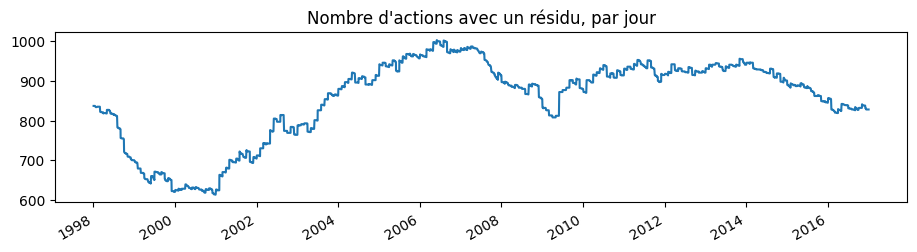

In [5]:
def residus_fama_french(K, fenetre=60):
    F = FF.reindex(D["jours"]).to_numpy()[:, :K]
    T, n = len(JOURS), R.shape[1]
    eps, actif, U = np.zeros((T, n), np.float32), np.zeros((T, n), bool), np.zeros((T, n, K), np.float32)
    for t in range(T):
        i = i0 + t
        s = ~np.isnan(R[i - fenetre:i]).any(0) & SEL[t]
        beta = np.linalg.lstsq(F[i - fenetre:i], R[i - fenetre:i, s], rcond=None)[0] if K else np.zeros((0, s.sum()))
        eps[t, s] = np.nan_to_num(R[i, s] - F[i] @ beta)
        actif[t, s], U[t, s] = ~np.isnan(R[i, s]), beta.T
    V = np.zeros((1, n + K, K), np.float32)
    V[0, n:] = np.eye(K)                       # le hedge porte sur les K portefeuilles de Fama-French
    return eps, actif, U, V


def residus_pca(K, fenetre=60, fenetre_cov=252):
    T, n = len(JOURS), R.shape[1]
    eps, actif = np.zeros((T, n), np.float32), np.zeros((T, n), bool)
    U, V = np.zeros((T, n, K), np.float32), np.zeros((T, n, K), np.float32)
    for t in range(T):
        i = i0 + t
        s = ~np.isnan(R[i - fenetre:i]).any(0) & SEL[t]
        auj = np.nan_to_num(R[i, s]).astype(np.float64)
        actif[t, s] = True
        if K == 0:
            eps[t, s] = auj
            continue
        C = np.nan_to_num(R[i - fenetre_cov:i, s]).astype(np.float64)
        vol = C.std(0)
        Z = (C - C.mean(0)) / vol
        lam, vec = scipy.linalg.eigh(Z @ Z.T, subset_by_index=(len(Z) - K, len(Z) - 1))   # K plus grandes valeurs propres
        lam, vec = lam[::-1], vec[:, ::-1]
        W = (Z.T @ vec) / np.sqrt(lam) / vol[:, None]          # poids des K portefeuilles propres
        h = C[-fenetre:]
        beta = np.linalg.lstsq(h @ W, h, rcond=None)[0]        # (K, actions)
        eps[t, s] = np.nan_to_num(auj - (auj @ W) @ beta)
        U[t, s], V[t, s] = beta.T, W
    return eps, actif, U, V


def residus_ipca(K, debut=420, fenetre=240, pas=12, iterations=1500, tol=1e-3):
    from sklearn.decomposition import PCA
    # Caractéristiques normalisées chaque mois (rang / nombre − 0,5), pour les couples (mois, action) de l'univers
    m = pd.read_csv(telecharger("caracteristiques.csv"))
    c = list(m.columns[5:])
    Zc = (m.groupby("date")[c].rank(method="first") / m.groupby("date")[c].transform("count") - 0.5).to_numpy()
    im, ip = np.searchsorted(D["mois"], m["date"]), np.searchsorted(D["permnos"], m["permno"])
    g = D["univers_mois"][im, ip]
    o = np.lexsort((ip[g], im[g]))
    im, ip, Zc, rm = im[g][o], ip[g][o], Zc[g][o], m["ret"].to_numpy()[g][o]
    M = len(D["mois"])
    bornes = np.r_[0, np.cumsum(np.bincount(im, minlength=M))]
    ZZ = np.stack([Zc[a:b].T @ Zc[a:b] for a, b in zip(bornes[:-1], bornes[1:])])    # (mois, 46, 46)
    ZR = np.stack([Zc[a:b].T @ rm[a:b] for a, b in zip(bornes[:-1], bornes[1:])])    # (mois, 46)

    def facteurs(zz, zr, G):        # f_t = (Γ' Z'Z Γ)^-1 Γ' Z'r
        return np.stack([np.linalg.solve(G.T @ a @ G, G.T @ b) for a, b in zip(zz, zr)])

    def gamma(zz, zr, f):           # Σ (Z'Z ⊗ f f') vec(Γ) = Σ Z'r ⊗ f
        L = zz.shape[1]
        A = np.einsum("tab,tc,td->acbd", zz, f, f).reshape(L * K, L * K)
        return np.linalg.solve(A, np.einsum("ta,tc->ac", zr, f).ravel()).reshape(L, K)

    # Γ ré-estimé chaque année sur les 240 mois précédents
    gammas, G = [], np.zeros((ZZ.shape[1], K))
    for w in range((M - debut) // pas):
        zz, zr = ZZ[debut + w * pas - fenetre:debut + w * pas], ZR[debut + w * pas - fenetre:debut + w * pas]
        f = PCA(K).fit((zr / np.diff(bornes)[debut + w * pas - fenetre:debut + w * pas, None]).T).components_.T if w == 0 else None
        for it in range(iterations if w == 0 else iterations // 2):
            if w > 0:
                f = facteurs(zz, zr, G)
            G_nouveau = gamma(zz, zr, f)
            if w == 0:
                f = facteurs(zz, zr, G_nouveau)
            ecart, G = np.abs(G_nouveau - G).max(), G_nouveau
            if it > 0 and ecart < tol:
                break
        gammas.append(G)

    # Chaque jour du mois mois : bêtas B = Z(mois-1) Γ, facteurs du jour = régression des rendements sur B
    T, n = len(JOURS), R.shape[1]
    eps, actif = np.zeros((T, n), np.float32), np.zeros((T, n), bool)
    U, V = np.zeros((T, n, K), np.float32), np.zeros((T, n, K), np.float32)
    col = np.cumsum(UNIVERS) - 1                                   # colonne de chaque action dans R
    for mois in range(debut, M):
        jours = np.flatnonzero(MOIS_PREC == mois - 1)
        a, b = bornes[mois - 1], bornes[mois]
        s = col[ip[a:b]]                                           # actions de l'univers ce mois-là
        r = R[i0 + jours][:, s].astype(np.float64)
        B = Zc[a:b] @ gammas[(mois - debut) // pas]
        P = B @ np.linalg.pinv(B.T @ B)
        res = r - (np.nan_to_num(r) @ P) @ B.T
        eps[np.ix_(jours, s)] = np.nan_to_num(res)
        actif[np.ix_(jours, s)] = ~np.isnan(r)
        U[np.ix_(jours, s)], V[np.ix_(jours, s)] = B, P
    return eps, actif, U, V


chemin = f"{DOSSIER}/residus_{FACTOR_MODEL}{K}.npz"
if not os.path.exists(chemin):
    calcul = {"FamaFrench": residus_fama_french, "PCA": residus_pca, "IPCA": residus_ipca}[FACTOR_MODEL]
    np.savez(chemin, **dict(zip(["eps", "actif", "U", "V"], calcul(K))))
EPS, ACTIF, U, V = (np.load(chemin)[k] for k in ["eps", "actif", "U", "V"])

residus = pd.DataFrame(EPS, index=JOURS, columns=D["permnos"][UNIVERS]).replace(0, np.nan)
print("Résidus :", residus.shape, "(jours x actions)")
residus.count(axis=1).plot(figsize=(11, 2.5), title="Nombre d'actions avec un résidu, par jour"); plt.show()

## 3. Le signal : les trois politiques

Pour chaque jour et chaque résidu, la politique lit les L derniers jours (30 en général) de **résidu cumulé**. Seuls les résidus sans donnée manquante sur la fenêtre sont tradés ce jour-là.

| Politique | Comment elle décide |
|---|---|
| **OUThreshold** | Ajuste un processus d'Ornstein-Uhlenbeck (retour à la moyenne). Si l'ajustement est bon (R² > 0,25) et que l'écart à la moyenne dépasse 1,25 écart-type, elle parie sur le retour (poids ±1). Pas d'apprentissage. |
| **FourierFFN** | Résume la fenêtre par ses coefficients de Fourier, puis un réseau dense (30 → 16 → 8 → 4 → 1) donne le poids. |
| **CNNTransformer** | Un CNN (2 convolutions de 8 filtres) repère des motifs locaux, un Transformer (4 têtes) les combine, une couche linéaire donne le poids. |

Les noms des couches sont ceux des auteurs, ce qui permet de charger leurs réseaux entraînés.

In [6]:
def entrees(data, L, fourier=False):
    """Fenêtres de L jours de résidu cumulé (jours, résidus, L) et résidus tradables (pas de zéro dans la fenêtre)."""
    cs = np.cumsum(data, 0)
    fen = sliding_window_view(cs, L, axis=0)[:-1] - np.concatenate([np.zeros_like(cs[:1]), cs[:-L - 1]])[:, :, None]
    sel = ~sliding_window_view(data == 0, L, axis=0)[:-1].any(-1)
    if fourier:                                                    # coefficients de Fourier : L//2+1 réels, L//2-1 imaginaires
        c = np.fft.rfft(fen, axis=-1)
        fen = np.concatenate([c.real, c.imag[:, :, 1:-1]], -1).astype(np.float32)
    return fen, sel


class OUThreshold(nn.Module):
    def __init__(self, L=30, seuil=1.25, r2_min=0.25):
        super().__init__()
        self.seuil, self.r2_min = seuil, r2_min

    def forward(self, x):                                          # x : (séquences, L) résidu cumulé
        X, Y = x[:, :-1], x[:, 1:]                                 # régression x(t+1) = a + b x(t)
        vx, vy = X.var(1) + 1e-16, Y.var(1) + 1e-16
        cov = ((X - X.mean(1, keepdim=True)) * (Y - Y.mean(1, keepdim=True))).mean(1)
        b = cov / vx
        a = Y.mean(1) - b * X.mean(1)
        sigma = torch.sqrt((Y - b[:, None] * X - a[:, None]).var(1) / (1 - b ** 2).abs())
        signal = (a / (1 - b) - Y[:, -1]) / sigma                  # écart à la moyenne, en écarts-types
        signal[~((b > 0) & (b < 1) & (sigma > 1e-16))] = 0         # pas de retour à la moyenne : pas de signal
        poids = (signal > self.seuil).float() - (signal < -self.seuil).float()
        return torch.nan_to_num(poids * (cov ** 2 / (vx * vy) > self.r2_min).float())


class FourierFFN(nn.Module):
    def __init__(self, L=30, couches=(16, 8, 4), dropout=0.25):
        super().__init__()
        torch.manual_seed(0)
        tailles = [L, *couches]
        self.hidden_layers = nn.ModuleList(nn.Sequential(nn.Linear(a, b), nn.ReLU(), nn.Dropout(dropout))
                                           for a, b in zip(tailles, tailles[1:]))
        self.final_layer = nn.Linear(tailles[-1], 1)

    def forward(self, x):                                          # x : (séquences, L) coefficients de Fourier
        for couche in self.hidden_layers:
            x = couche(x)
        return self.final_layer(x).squeeze(-1)


class BlocCNN(nn.Module):
    def __init__(self, entree=1, sortie=8, taille=2):
        super().__init__()
        self.conv1, self.conv2 = nn.Conv1d(entree, sortie, taille), nn.Conv1d(sortie, sortie, taille)
        self.pad = nn.ConstantPad1d((taille - 1, 0), 0)
        self.norm1, self.norm2 = nn.InstanceNorm1d(entree), nn.InstanceNorm1d(sortie)

    def forward(self, x):                                          # x : (séquences, 1, L)
        x = self.norm1(x)
        y = self.norm2(torch.relu(self.conv1(self.pad(x))))
        y = torch.relu(self.conv2(self.pad(y)))
        return y + x.repeat(1, y.shape[1] // x.shape[1], 1)        # connexion résiduelle


class CNNTransformer(nn.Module):
    def __init__(self, L=30, filtres=8, tetes=4, dropout=0.25):
        super().__init__()
        torch.manual_seed(0)
        self.convBlocks = nn.ModuleList([BlocCNN(1, filtres)])
        self.encoder = nn.TransformerEncoderLayer(filtres, tetes, dim_feedforward=2 * filtres, dropout=dropout)
        self.linear = nn.Linear(filtres, 1)

    def forward(self, x):                                          # x : (séquences, L)
        x = self.convBlocks[0](x[:, None, :])                      # (séquences, 8, L)
        x = self.encoder(x.permute(2, 0, 1))                       # (L, séquences, 8)
        return self.linear(x[-1]).squeeze(-1)                      # un poids par séquence


POLITIQUES = {"OUThreshold": OUThreshold, "FourierFFN": FourierFFN, "CNNTransformer": CNNTransformer}


def appliquer(modele, x, bloc=50_000 if device == "cuda" else 10_000):
    """Passe les séquences par blocs (avec recalcul au backward) pour tenir en mémoire."""
    if len(x) <= bloc:
        return modele(x)
    if torch.is_grad_enabled():
        return torch.cat([checkpoint(modele, x[i:i + bloc], use_reentrant=False) for i in range(0, len(x), bloc)])
    return torch.cat([modele(x[i:i + bloc]) for i in range(0, len(x), bloc)])

## 4. L'allocation : portefeuille, entraînement et test

Chaque jour :
1. les poids des résidus deviennent des positions en actions grâce à la composition ;
2. tout est divisé par la somme des |positions| (levier de 1) ;
3. le rendement du portefeuille vaut Σ poids × résidus du jour, moins les coûts éventuels.

Les réglages d'une **expérience** (`EXPERIENCES`) sont ceux des fichiers de configuration des auteurs. L'expérience principale est le cas par défaut, les autres servent à la section 7.

In [7]:
EXPERIENCES = {
    "principale":     dict(),                                       # résultats principaux du papier
    "meanvar":        dict(objectif="meanvar"),                     # maximiser rendement − volatilité
    "lookback60":     dict(L=60),                                   # fenêtres de 60 jours au lieu de 30
    "constant-4year": dict(reentrainer=False),                      # un seul modèle, entraîné sur 1998-2001
    "constant-8year": dict(reentrainer=False, duree=2012),          # un seul modèle, entraîné sur 1998-2005
    "frictions":      dict(couts=(0.0005, 0.0001)),                 # 5 pb par transaction, 1 pb par jour de short
    "multiholding":   dict(detention=5),                            # chaque position gardée 5 jours
    "overlapping":    dict(lissage=5),                              # poids moyennés sur 5 jours
}
DEFAUT = dict(L=30, duree=1000, objectif="sharpe", reentrainer=True, couts=(0, 0), detention=1, lissage=None)

GARDER = (EPS != 0).sum(0) >= 30                                   # résidus avec assez de données
EPS, ACTIF, U = EPS[:, GARDER], ACTIF[:, GARDER], U[:, GARDER]
COLONNE = np.flatnonzero(GARDER)                                   # colonne de l'action de chaque résidu


def positions(w, t0, cols):
    """Positions en actions des portefeuilles de résidus w (jours, résidus), jours t0 et suivants."""
    jours = slice(t0, t0 + len(w))
    wa = w * torch.as_tensor(ACTIF[jours][:, cols], device=device)
    p = torch.zeros(len(w), V.shape[1], device=device)
    p[:, COLONNE[cols]] = wa                                       # long l'action...
    expo = torch.einsum("tn,tnk->tk", wa, torch.as_tensor(U[jours][:, cols], device=device))
    Vj = torch.as_tensor(V[jours] if len(V) > 1 else V, device=device)
    return p - torch.einsum("tk,tmk->tm", expo, Vj.expand(len(w), -1, -1))   # ... short son hedge


def moyenne_mobile(w, n):
    c = torch.cumsum(w, 0)
    c = torch.cat([c[:n], c[n:] - c[:-n]])
    return c / torch.clamp(torch.arange(1, len(w) + 1, device=w.device), max=n)[:, None]


def portefeuille(w, t0, x, cols=slice(None)):
    """Normalise les poids (levier de 1) et renvoie (poids des résidus, positions en actions ou None)."""
    p = positions(w, t0, cols) if COMPOSITION else None
    levier = (p if COMPOSITION else w).abs().sum(1, keepdim=True) + 1e-8
    w, p = w / levier, (p / levier if COMPOSITION else None)
    if x["lissage"]:                                               # expérience 'overlapping'
        w = moyenne_mobile(w / (w.abs().sum(1, keepdim=True) + 1e-8), x["lissage"])
        p = positions(w, t0, cols) if COMPOSITION else None
    return w, p


def rendements(w, p, r, x):
    """Rendement quotidien du portefeuille, net des coûts de transaction et de short."""
    pos = p if p is not None else w
    tc, hc = x["couts"]
    turnover = torch.cat([torch.zeros(1, device=device), (pos[1:] - pos[:-1]).abs().sum(1)])
    B = x["detention"]
    if B == 1:
        return (w * r).sum(1) - tc * turnover - hc * pos.clamp(max=0).abs().sum(1)
    out = torch.zeros(len(r), device=device)                       # expérience 'multiholding'
    for t in range(B, len(r)):                                     # la position ouverte en t-B+1 est gardée B jours
        brut = torch.cumprod(1 + (w[t - B + 1] * r[t - B + 1:t + 1]).sum(1), 0)[-1] - 1
        out[t] = brut - tc * (pos[t] - pos[t - B]).abs().sum() - hc * pos[t].clamp(max=0).abs().sum()
    return out / B


def sharpe(r, B=1):
    if B == 1:
        return r.mean() * 252 / (r.std() * torch.sqrt(torch.tensor(252.0)) + 1e-8)
    x = r * B                                                      # détention de B jours : moyenne sur les B décalages
    return torch.stack([torch.sqrt(torch.tensor(252 / B)) * x[i::B].mean() / x[i::B].std() for i in range(B)]).mean()


def perte(r, x):
    if x["objectif"] == "meanvar":
        return -(r.mean() * 252 - (r.std() * torch.sqrt(torch.tensor(252.0)) + 1e-8))
    return -sharpe(r, x["detention"])


def entrainer(modele, t0, x, lot=125):
    """Entraîne le modèle sur les jours [t0, t0 + durée)."""
    L = x["L"]
    cols = (EPS[t0:t0 + x["duree"]] != 0).sum(0) >= 30              # résidus avec assez de données sur la fenêtre
    data = EPS[t0:t0 + x["duree"], cols]
    fen, sel = entrees(data, L, isinstance(modele, FourierFFN))
    r_jours = torch.as_tensor(data, device=device)
    opt = torch.optim.Adam(modele.parameters(), lr=1e-3)
    modele.to(device).train()
    for epoque in range(EPOCHS):
        for d in range(0, len(fen), lot):
            f = min(d + lot, len(fen))
            w = torch.zeros(f - d, cols.sum(), device=device)
            w[torch.as_tensor(sel[d:f])] = appliquer(modele, torch.as_tensor(fen[d:f][sel[d:f]], device=device))
            w, p = portefeuille(w, t0 + L + d, x, cols)
            loss = perte(rendements(w, p, r_jours[L + d:L + f], x), x)
            opt.zero_grad()
            loss.backward()
            opt.step()
        if epoque % 10 == 0 or epoque == EPOCHS - 1:
            print(f"   époque {epoque + 1}/{EPOCHS} : objectif sur le dernier lot {-loss.item():.2f}")


@torch.no_grad()
def tester(modele, t0, x, duree=125):
    """Rendements, turnover et part short du portefeuille sur les jours [t0, t0 + duree)."""
    L = x["L"]
    data = EPS[t0 - L:t0 + duree]
    fen, sel = entrees(data, L, isinstance(modele, FourierFFN))
    modele.to(device).eval()
    w = torch.zeros(len(fen), data.shape[1], device=device)
    w[torch.as_tensor(sel)] = appliquer(modele, torch.as_tensor(fen[sel], device=device))
    w, p = portefeuille(w, t0, x)
    pos = p if p is not None else w
    r = rendements(w, p, torch.as_tensor(data[L:], device=device), x)
    turnover = torch.cat([(pos[1:] - pos[:-1]).abs().sum(1).mean()[None], (pos[1:] - pos[:-1]).abs().sum(1)])
    return pd.DataFrame({"rendement": r.cpu(), "turnover": turnover.cpu(), "short": pos.clamp(max=0).abs().sum(1).cpu()},
                        index=JOURS[t0:t0 + len(w)])

## 5. Le backtest en fenêtres glissantes

Fenêtre k : entraînement sur les jours [125k, 125k + 1000), test sur les 125 jours suivants. Avec les réglages principaux, cela fait 31 fenêtres et un test continu de fin 2001 à fin 2016.

D'où viennent les modèles :
- **OUThreshold** n'a rien à apprendre.
- **`TRAINING = "pretrained"`** charge les réseaux des auteurs. Ils ont été entraînés sur IPCA 5 : c'est la stratégie exacte du papier pour IPCA 5, et une approximation pour les autres hedges. Fourier+FFN n'en a que pour `principale` et `meanvar`.
- **`TRAINING = "train"`** entraîne ici. Chaque modèle est enregistré dans `DOSSIER/modeles/` et rechargé s'il existe déjà.

In [8]:
def backtest(experience="principale"):
    x = {**DEFAUT, **EXPERIENCES[experience]}
    entraine = POLITIQUE != "OUThreshold"
    nom = f"{FACTOR_MODEL}{K}_{POLITIQUE}_{experience}" + (f"_{TRAINING}" if entraine else "") \
          + (f"_{EPOCHS}ep" if entraine and TRAINING == "train" else "") \
          + ("" if COMPOSITION else "_sans-composition") + (f"_essai{MAX_WINDOWS}" if MAX_WINDOWS else "")
    if entraine and TRAINING == "pretrained":
        dossier_auteurs = f"{DOSSIER}/modeles_auteurs/{experience}"
        zipfile.ZipFile(telecharger(f"modeles_{experience}.zip")).extractall(dossier_auteurs)
    if entraine and TRAINING == "train":
        os.makedirs(f"{DOSSIER}/modeles/{nom}", exist_ok=True)

    n_fenetres = min((len(EPS) - x["duree"]) // 125 + 1, MAX_WINDOWS or 99)
    resultats = []
    for k in range(n_fenetres):
        if k == 0 or x["reentrainer"] or not entraine:
            modele = POLITIQUES[POLITIQUE](x["L"])
            if entraine and TRAINING == "pretrained":
                fichier = glob.glob(f"{dossier_auteurs}/*{POLITIQUE}__*__subperiod{k}.tar")
                if not fichier:
                    raise FileNotFoundError(f"Pas de réseau des auteurs pour {POLITIQUE} / {experience} : utilise TRAINING = 'train'")
                poids = torch.load(fichier[0], map_location="cpu", weights_only=False)["model_state_dict"]
                modele.load_state_dict({k.removeprefix("module."): v for k, v in poids.items()})   # certains fichiers ont un préfixe
            elif entraine:
                fichier = f"{DOSSIER}/modeles/{nom}/fenetre{k}.pt"
                if os.path.exists(fichier):
                    modele.load_state_dict(torch.load(fichier, map_location="cpu"))
                else:
                    print(f"Fenêtre {k + 1}/{n_fenetres} : entraînement")
                    entrainer(modele, 125 * k, x)
                    torch.save(modele.state_dict(), fichier)
        resultats.append(tester(modele, 125 * k + x["duree"], x))
        print(f"{nom} | fenêtre {k + 1}/{n_fenetres} ({resultats[-1].index[0]:%Y-%m}) : "
              f"Sharpe {sharpe(torch.tensor(resultats[-1]['rendement'].values)):.2f}")

    resultat = pd.concat(resultats)
    resultat.to_csv(f"{DOSSIER}/resultats/{nom}.csv")
    print(f"==> {nom} : Sharpe {sharpe(torch.tensor(resultat['rendement'].values)):.2f}\n")
    return nom, resultat


NOM, resultat = backtest("principale")

Téléchargement de modeles_principale.zip
IPCA5_CNNTransformer_principale_pretrained | fenêtre 1/31 (2001-12) : Sharpe 5.66
IPCA5_CNNTransformer_principale_pretrained | fenêtre 2/31 (2002-06) : Sharpe 5.41
IPCA5_CNNTransformer_principale_pretrained | fenêtre 3/31 (2002-12) : Sharpe 6.09
IPCA5_CNNTransformer_principale_pretrained | fenêtre 4/31 (2003-06) : Sharpe 10.41
IPCA5_CNNTransformer_principale_pretrained | fenêtre 5/31 (2003-12) : Sharpe 5.03
IPCA5_CNNTransformer_principale_pretrained | fenêtre 6/31 (2004-06) : Sharpe 8.55
IPCA5_CNNTransformer_principale_pretrained | fenêtre 7/31 (2004-12) : Sharpe 5.22
IPCA5_CNNTransformer_principale_pretrained | fenêtre 8/31 (2005-06) : Sharpe 6.15
IPCA5_CNNTransformer_principale_pretrained | fenêtre 9/31 (2005-12) : Sharpe 5.94
IPCA5_CNNTransformer_principale_pretrained | fenêtre 10/31 (2006-06) : Sharpe 7.09
IPCA5_CNNTransformer_principale_pretrained | fenêtre 11/31 (2006-12) : Sharpe 4.83
IPCA5_CNNTransformer_principale_pretrained | fenêtre 1

## 6. Résultats, et comparaison avec tes autres expériences

Chaque expérience est enregistrée dans `DOSSIER/resultats/`. Le tableau compare toutes tes expériences principales complètes (tous hedges et toutes politiques, hors essais) **sur leurs jours communs**. Les expériences de robustesse sont comparées à part, en section 7.

- **Sharpe, rendement et volatilité** sont annualisés.
- **Drawdown max** est la pire perte depuis un sommet.
- **Alpha FF8** est le rendement annuel non expliqué par les 8 facteurs de Fama-French, avec son t-stat.

,Début,Sharpe,Rendement,Volatilité,Drawdown max,Alpha FF8,t-stat alpha
IPCA5_CNNTransformer_principale_pretrained,2001-12,4.09,8.5%,2.1%,-2.4%,8.1%,15.4


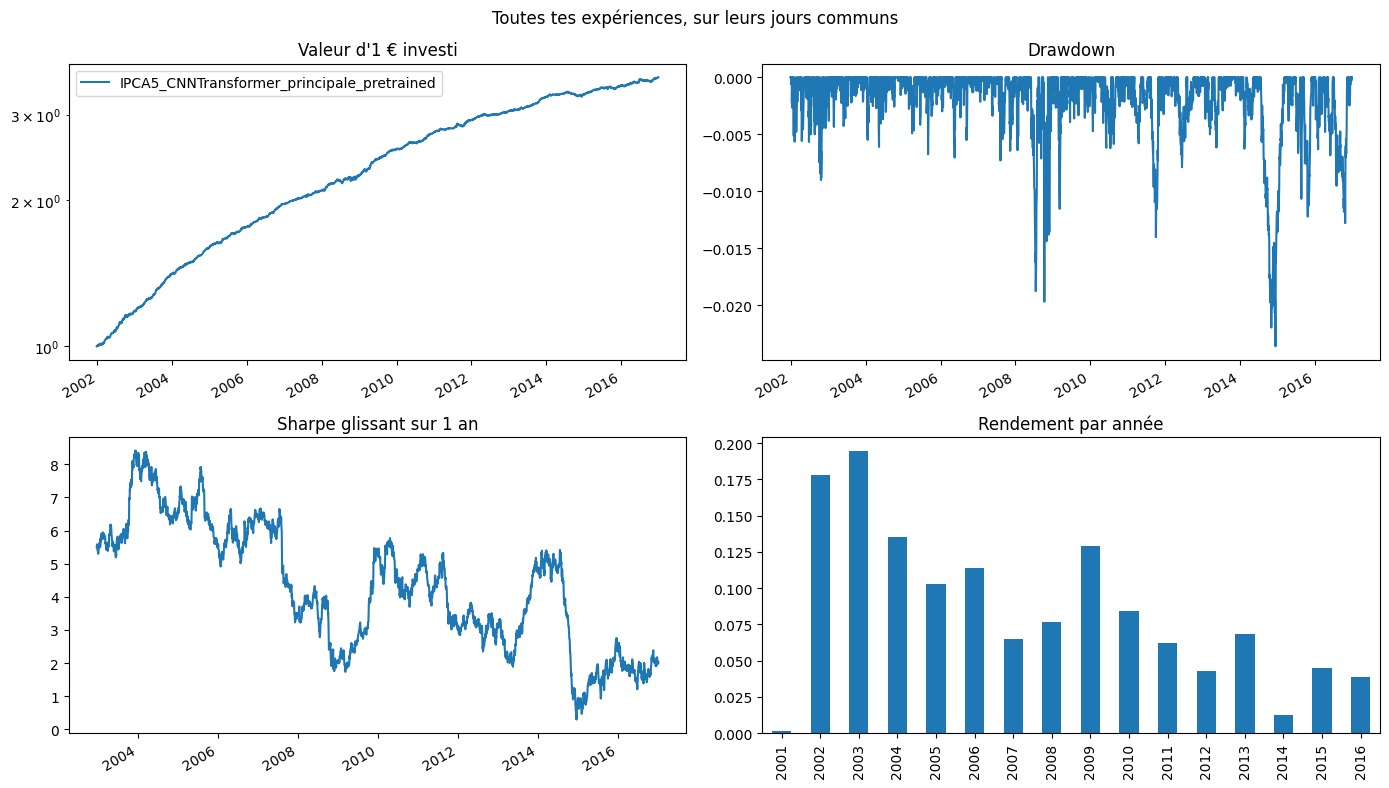

In [9]:
import statsmodels.api as sm


def statistiques(r):
    capital = (1 + r).cumprod()
    X = sm.add_constant(FF.reindex(r.index.strftime("%Y%m%d").astype(int)).iloc[:, :8].to_numpy())
    reg = sm.OLS(r.to_numpy(), X).fit()
    return pd.Series({"Début": f"{r.index[0]:%Y-%m}", "Sharpe": r.mean() / r.std() * np.sqrt(252),
                      "Rendement": r.mean() * 252, "Volatilité": r.std() * np.sqrt(252),
                      "Drawdown max": (capital / capital.cummax() - 1).min(),
                      "Alpha FF8": reg.params[0] * 252, "t-stat alpha": reg.tvalues[0]})


def tableau(rdt):
    return rdt.apply(lambda r: statistiques(r.dropna())).T.style.format(
        {"Sharpe": "{:.2f}", "t-stat alpha": "{:.1f}", "Rendement": "{:.1%}",
         "Volatilité": "{:.1%}", "Drawdown max": "{:.1%}", "Alpha FF8": "{:.1%}"})


def graphiques(rdt, titre=""):
    fig, ax = plt.subplots(2, 2, figsize=(14, 8))
    capital = (1 + rdt).cumprod()
    capital.plot(ax=ax[0, 0], logy=True, title="Valeur d'1 € investi")
    (capital / capital.cummax() - 1).plot(ax=ax[0, 1], legend=False, title="Drawdown")
    (rdt.rolling(252).mean() / rdt.rolling(252).std() * np.sqrt(252)).plot(ax=ax[1, 0], legend=False, title="Sharpe glissant sur 1 an")
    (1 + rdt).groupby(rdt.index.year).prod().sub(1).plot.bar(ax=ax[1, 1], legend=False, title="Rendement par année")
    fig.suptitle(titre)
    plt.tight_layout()
    plt.show()


series = {os.path.basename(f)[:-4]: pd.read_csv(f, index_col=0, parse_dates=True)["rendement"]
          for f in sorted(glob.glob(f"{DOSSIER}/resultats/*_principale*.csv")) if "_essai" not in f}
rdt = pd.DataFrame(series).dropna() if series else resultat[["rendement"]].rename(columns={"rendement": NOM})
display(tableau(rdt))
graphiques(rdt, "Toutes tes expériences, sur leurs jours communs")
if rdt.shape[1] > 1:
    display(rdt.corr().style.format("{:.2f}").set_caption("Corrélation des rendements quotidiens"))

## 7. Expériences de robustesse

La même stratégie (même hedge, même politique, même `TRAINING`) est relancée avec les réglages des autres expériences du papier :

| Expérience | Ce qui change |
|---|---|
| `meanvar` | l'objectif est rendement − volatilité au lieu du Sharpe |
| `lookback60` | la politique lit 60 jours au lieu de 30 |
| `constant-4year` | un seul modèle, entraîné sur 1998-2001, gardé jusqu'en 2016 |
| `constant-8year` | un seul modèle, entraîné sur 1998-2005 (test à partir de 2006) |
| `frictions` | coûts de 5 pb par transaction et 1 pb par jour de short, à l'entraînement et au test |
| `multiholding` | chaque position est gardée 5 jours |
| `overlapping` | les poids sont moyennés sur 5 jours |

Mets `ROBUSTESSE = True` pour les lancer. Chaque expérience est enregistrée comme les autres. Avec `TRAINING = "train"`, chacune demande un entraînement complet.

In [10]:
if ROBUSTESSE:
    robustesse = {"principale": resultat["rendement"]}
    for experience in [e for e in EXPERIENCES if e != "principale"]:
        try:
            robustesse[experience] = backtest(experience)[1]["rendement"]
        except FileNotFoundError as erreur:
            print(f"{experience} ignorée : {erreur}\n")
    rob = pd.DataFrame(robustesse)
    display(tableau(rob))                                          # chaque expérience sur sa propre période
    graphiques(rob, f"Robustesse : {FACTOR_MODEL} {K}, {POLITIQUE}")